# 02. Feature engineering: what we add, why, and what the ablation showed

**Project:** Kaggle House Prices. **Stage:** after cleaning (notebook 01), before modelling.

This notebook is deliberately *thin*: every computation lives in `src/houseprices/` (`cleaning`, `features`, `preprocess`, `data`, `registry`) and the notebook only calls it and displays results. That is the same code the experiments run, so what you read here is what was evaluated.

Two ideas to keep in mind while reading:

1. **Feature groups are pure functions.** They only combine columns of the same row (for example `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`). Nothing is learned from other rows, so they cannot leak information between training and validation data.
2. **Anything that is *learned* from data (medians, which columns are skewed, one-hot categories) lives in `preprocess.py` and is refit on each training fold.** That is what keeps cross-validation honest.

In [1]:
# Resolve the project root the same way notebook 01 does: walk up until data_description.txt is found.
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "data_description.txt").exists():
    if root == root.parent:
        raise FileNotFoundError("Project root (data_description.txt) not found")
    root = root.parent
os.chdir(root)
print("Working directory:", Path.cwd())

Working directory: C:\Users\Enrique Baena\Desktop\HousePricingKaglle


In [2]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from houseprices import cleaning, data, features, preprocess, registry

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Load the development data with the "all" feature set

`data.load_development_data(...)` with the "all" feature set is the single entry point every experiment uses. It cleans train and test with the same rules, **sets aside the holdout rows** (a fixed 20% we never look at while choosing models) and builds the features. We keep only the development rows for analysis. For the holdout we print nothing but its row count.

In [3]:
# "all" is our shorthand for base plus the five engineered groups (it is not an alias in data.py).
ALL = "base+areas+baths+ages+quality_interactions+ordinal_quality"
dev = data.load_development_data(ALL, with_holdout_split=True)
print("development rows  :", len(dev.X))
print("holdout rows      :", len(dev.X_holdout), "(not inspected anywhere in this notebook)")
print("competition test  :", len(dev.X_test))
print("feature groups    :", dev.feature_groups)
print("feature columns   :", dev.X.shape[1] - 1, "(plus the Id column, which model pipelines drop)")

development rows  : 1241
holdout rows      : 219 (not inspected anywhere in this notebook)
competition test  : 1459
feature groups    : ['base', 'areas', 'baths', 'ages', 'quality_interactions', 'ordinal_quality']
feature columns   : 99 (plus the Id column, which model pipelines drop)


## 2. The feature groups, one by one

`features.FEATURE_SETS` holds one function per group. `base` is everything the cleaning step produced (minus `Id`, `SalePrice` and the audit flags). The other five groups *add* columns:

- **areas**: `TotalSF` (basement + both floors) and `TotalPorchSF` (the five porch/deck areas). Price scales with total living space, and a single clean total is easier for a linear model than three separate columns.
- **baths**: `TotalBath`, counting half baths as 0.5. Four sparse count columns become the number buyers actually think about.
- **ages**: `HouseAge`, `RemodAge`, `GarageAge` at the time of sale. Depreciation depends on age, not on the calendar year, and a linear model cannot subtract two columns by itself. Impossible years are handled without editing data: a house sold before it was built gets age 0, and an implausible garage year becomes a missing `GarageAge` that is imputed inside each fold.
- **quality_interactions**: `OverallQual * GrLivArea` and `OverallQual * TotalSF`. A quality premium is worth more on a bigger house, an interaction a linear model cannot form alone.
- **ordinal_quality**: numeric twins (`ExterQual_ord`, ...) of the quality labels Po < Fa < TA < Gd < Ex, so a model can learn one monotone slope instead of five unrelated one-hot columns.

Below, the columns each group contributes and three example development rows.

In [4]:
train_clean, test_clean, _ = cleaning.clean_train_test()   # used only to read column names and the flags
engineered = ["areas", "baths", "ages", "quality_interactions", "ordinal_quality"]
group_cols = {g: list(features.FEATURE_SETS[g](train_clean.head(5)).columns) for g in engineered}
extra = sum(group_cols.values(), [])
base_cols = [c for c in dev.X.columns if c != "Id" and c not in extra]
print(f"base: {len(base_cols)} columns, e.g. {base_cols[:8]} ...")
for g, cols in group_cols.items():
    print(f"\n{g}: {len(cols)} columns -> {cols}")

base: 81 columns, e.g. ['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour'] ...

areas: 2 columns -> ['TotalSF', 'TotalPorchSF']

baths: 1 columns -> ['TotalBath']

ages: 3 columns -> ['HouseAge', 'RemodAge', 'GarageAge']

quality_interactions: 2 columns -> ['OverallQual_x_GrLivArea', 'OverallQual_x_TotalSF']

ordinal_quality: 10 columns -> ['ExterQual_ord', 'ExterCond_ord', 'BsmtQual_ord', 'BsmtCond_ord', 'HeatingQC_ord', 'KitchenQual_ord', 'FireplaceQu_ord', 'GarageQual_ord', 'GarageCond_ord', 'PoolQC_ord']


In [5]:
for g in engineered:
    print(f"--- {g} ---")
    display(dev.X[group_cols[g]].head(3))

--- areas ---


,TotalSF,TotalPorchSF
0,2566,61
1,2524,298
2,2706,42


--- baths ---


,TotalBath
0,3.5
1,2.5
2,3.5


--- ages ---


,HouseAge,RemodAge,GarageAge
0,5,5,5.0
1,31,31,31.0
2,7,6,7.0


--- quality_interactions ---


,OverallQual_x_GrLivArea,OverallQual_x_TotalSF
0,11970,17962
1,7572,15144
2,12502,18942


--- ordinal_quality ---


,ExterQual_ord,ExterCond_ord,BsmtQual_ord,BsmtCond_ord,HeatingQC_ord,KitchenQual_ord,FireplaceQu_ord,GarageQual_ord,GarageCond_ord,PoolQC_ord
0,4.0,3.0,4.0,3.0,5.0,4.0,0.0,3.0,3.0,0.0
1,3.0,3.0,4.0,3.0,5.0,3.0,3.0,3.0,3.0,0.0
2,4.0,3.0,4.0,3.0,5.0,4.0,3.0,3.0,3.0,0.0


## 3. Skewness and the in-fold log1p transform

Many size columns (`LotArea`, `MiscVal`, porch areas, ...) are strongly right-skewed: most houses are small, a few are huge. Linear models are sensitive to such long tails, so `preprocess.SkewLog1pTransformer` applies `log1p` to numeric columns whose **training-fold skewness exceeds 0.75 and whose minimum is not negative**.

The list of columns is a *fitted statistic*, so it is learned from the training rows only. In the real experiments this happens **inside every cross-validation fold**. In this notebook we fit it once on the development rows purely to *illustrate* the effect. Trees do not need it because they are invariant to monotone transformations.

In [6]:
numeric_cols, _ = preprocess.split_columns(dev.X.drop(columns=["Id"]))
Xn = dev.X[numeric_cols]
skewer = preprocess.SkewLog1pTransformer(threshold=0.75).fit(Xn)          # development rows only
skew_before = Xn[skewer.skewed_columns_].skew().sort_values(ascending=False)
after = pd.DataFrame(skewer.transform(Xn), columns=numeric_cols, index=Xn.index)
skew_after = after[skewer.skewed_columns_].skew()
summary = pd.DataFrame({"skew_before": skew_before, "skew_after": skew_after[skew_before.index]})
print(f"{len(skewer.skewed_columns_)} of {len(numeric_cols)} numeric columns selected")
summary.head(10).round(2)

28 of 53 numeric columns selected


,skew_before,skew_after
MiscVal,23.74,5.20
PoolQC_ord,14.70,13.79
PoolArea,13.66,13.23
MasVnrConflict,13.22,13.22
LotArea,13.13,-0.31
3SsnPorch,10.92,8.05
LowQualFinSF,8.92,7.47
KitchenAbvGr,4.50,3.80
BsmtFinSF2,4.34,2.60
BsmtHalfBath,4.25,4.04


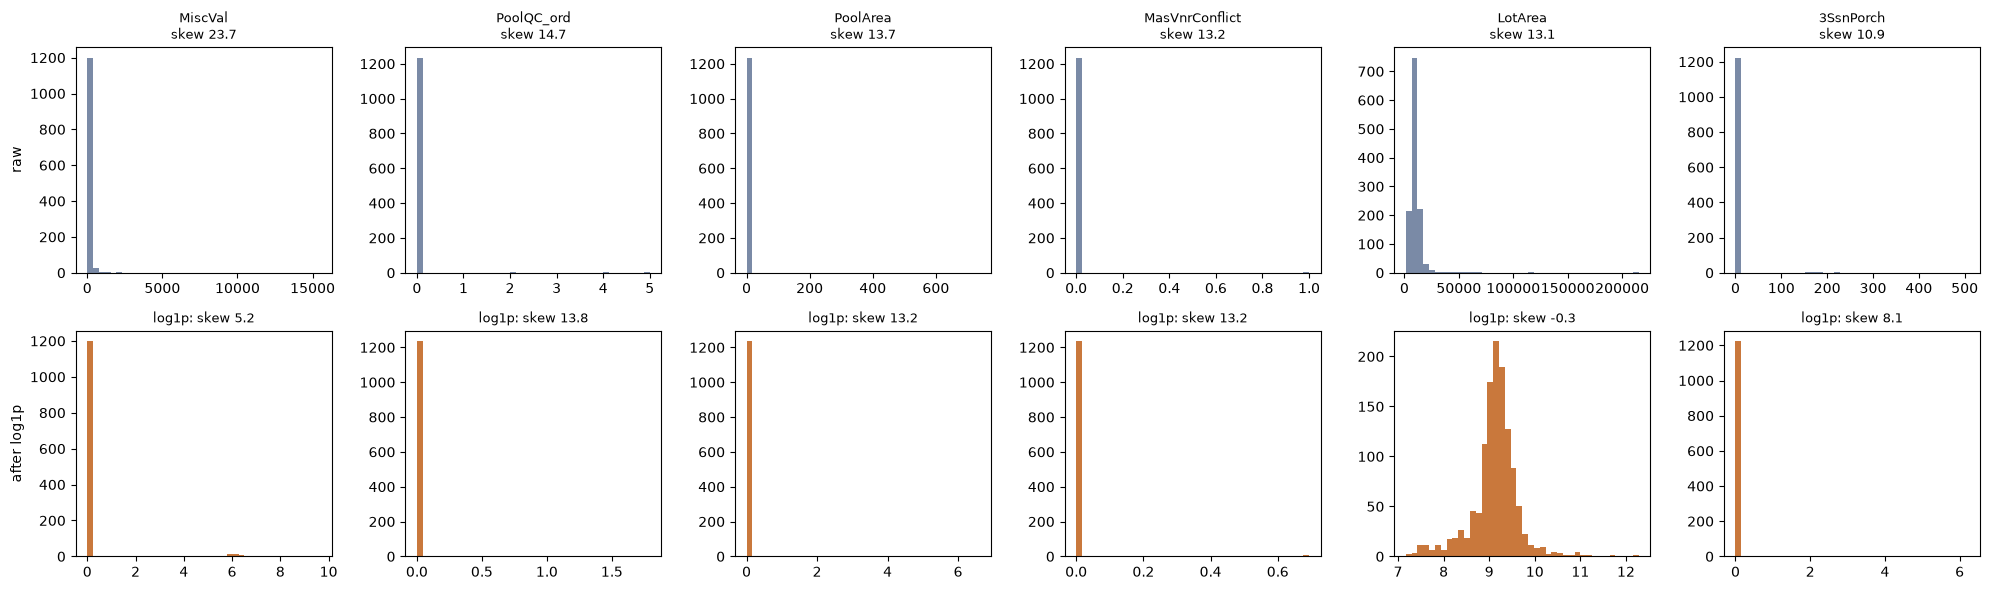

In [7]:
top6 = list(skew_before.index[:6])
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for j, col in enumerate(top6):
    axes[0, j].hist(Xn[col].dropna(), bins=40, color="#7a8aa6")
    axes[0, j].set_title(f"{col}\nskew {skew_before[col]:.1f}", fontsize=9)
    axes[1, j].hist(after[col].dropna(), bins=40, color="#c9783c")
    axes[1, j].set_title(f"log1p: skew {skew_after[col]:.1f}", fontsize=9)
axes[0, 0].set_ylabel("raw")
axes[1, 0].set_ylabel("after log1p")
plt.tight_layout()
plt.show()

The six most skewed columns split into two kinds. `LotArea` is the success story: continuous, skew 13.1 before and about -0.3 after `log1p`, because a few giant lots no longer dominate. The others (`MiscVal`, `PoolQC_ord`, `PoolArea`, `MasVnrConflict`, `3SsnPorch`) are zero for almost every house. Their skewness barely moves, because a transform cannot spread identical values; `MiscVal` improves because its non-zero amounts vary widely. So the gain for linear models comes mainly from the continuous size columns that the selection picks up further down the list.

## 4. The anomaly flags: a finding about the data, not a feature

Three audit flags mark impossible years: `GarageYrBltImplausible` (garage built after the sale), `SoldBeforeBuilt` and `RemodBeforeBuilt`. They are produced by `cleaning.add_anomaly_flags` and are never part of `base`. The director allowed testing them as an extra group, but look at where they are non-zero.

In [8]:
flag_cols = features.ANOMALY_FLAG_COLS
print("TRAIN: rows flagged per column")
print(train_clean[flag_cols].sum().to_string())
print("\nTEST: rows flagged per column")
print(test_clean[flag_cols].sum().to_string())
test_clean.loc[test_clean[flag_cols].any(axis=1), ["Id", "YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold", *flag_cols]]

TRAIN: rows flagged per column
GarageYrBltImplausible    0
SoldBeforeBuilt           0
RemodBeforeBuilt          0

TEST: rows flagged per column
GarageYrBltImplausible    2
SoldBeforeBuilt           1
RemodBeforeBuilt          1


,Id,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold,GarageYrBltImplausible,SoldBeforeBuilt,RemodBeforeBuilt
416,1877,2002,2001,2002.0,2009,False,False,True
1089,2550,2008,2009,2008.0,2007,True,True,False
1132,2593,2006,2007,2207.0,2007,True,False,False


All three flags are **zero for every training house** and non-zero only for three *test* houses: Id 2593 (garage year 2207), Id 2550 (sold before it was built, and also an implausible garage year) and Id 1877 (remodelled before it was built). A feature that is constant in the training data cannot be learned from, so `base+anomaly_flags` can never differ from `base` and we excluded it from the ablation. The useful consequence is on the other side: the `ages` group clips negative ages to 0 and turns the 2207 garage year into a missing value that is imputed in-fold, so these three test houses cannot produce nonsense predictions.

## 5. The ablation, read from the experiment registry

Every experiment is one line in `experiments/registry.jsonl`. Below we load it and rebuild the pivot for experiments E003 to E042: feature set by model, cell = mean cross-validated RMSE on log price (5 shuffled folds, seed 42, **lower is better**). For reference, predicting the mean price gives about 0.399.

In [9]:
reg = registry.load_registry()
reg["n"] = reg["id"].str[1:].astype(int)


def _kw(v):
    return json.loads(v) if isinstance(v, str) else (v or {})


def tidy(df):
    df = df.copy()
    pk = df["builder_kwargs"].map(lambda v: _kw(v).get("preprocessor_kwargs", {}) or {})
    df["model"] = df["builder"].str.split(":").str[1].str.replace("build_", "")
    df["log1p_on"] = pk.map(lambda d: bool(d.get("skew_log1p", False)))
    df["lotfrontage"] = pk.map(lambda d: d.get("lotfrontage", "neighborhood_median"))
    df["fs"] = df["feature_set"].str.replace(ALL, "all", regex=False) + np.where(df["log1p_on"], " | skew log1p", "")
    return df


abl = tidy(reg[(reg.n >= 3) & (reg.n <= 42)])
pivot = abl.pivot_table(index="fs", columns="model", values="cv_mean")[["ridge", "elasticnet", "xgboost"]]
head = ["base", "base+areas", "base+baths", "base+ages", "base+quality_interactions", "base+ordinal_quality", "all"]
pivot.loc[head + [i for i in pivot.index if i not in head]].round(4)

model,ridge,elasticnet,xgboost
fs,,,
base,0.1409,0.1379,0.1487
base+areas,0.1410,0.1379,0.1453
base+baths,0.1409,0.1375,0.1432
base+ages,0.1409,0.1379,0.1466
base+quality_interactions,0.1385,0.1350,0.1388
base+ordinal_quality,0.1412,0.1378,0.1470
all,0.1387,0.1350,0.1356
all | skew log1p,0.1304,0.1256,NaN
base | skew log1p,0.1319,0.1285,NaN


**How to read it.** The long row names are `all` with one group removed (leave-one-out). Differences below about 0.001 are noise at 5 folds; the registry decisions use a one-paired-standard-error rule and are *provisional* until the finalists are re-checked with RepeatedKFold 5x3 (decision D14).

- **quality_interactions is the group that matters.** Alone it improves all three models, and removing it from `all` is the only leave-one-out change that clearly hurts. It is the interaction linear models cannot build themselves.
- **areas, baths, ages and ordinal_quality are individually small**, at most about 0.003 for the linear models. XGBoost gains somewhat from `areas` and `baths`, because totals save it splits.
- **ordinal_quality does not pay for itself** at default settings; removing it from `all` slightly improves the two linear models (0.0004 and 0.0006) and slightly hurts XGBoost (0.0012), all within noise. We keep the full set "all" anyway (D11): pruning at untuned hyper-parameters would fit fold noise, and the question is revisited on the finalists.
- **The skew transform is the largest single gain**, about 0.009 for both linear models, on `base` and on `all` alike (D12). The best score in the table is `all | skew log1p` with ElasticNet. Trees never get the transform.

In [10]:
skewed = abl[abl["log1p_on"]].pivot_table(index="fs", columns="model", values="cv_mean")[["ridge", "elasticnet"]]
plain = pivot.loc[["base", "all"], ["ridge", "elasticnet"]]
plain.index = [i + " | skew log1p" for i in plain.index]
skewed.join(plain.rename(columns=lambda c: c + " (no skew)")).round(4)

model,ridge,elasticnet,ridge (no skew),elasticnet (no skew)
fs,,,,
all | skew log1p,0.1304,0.1256,0.1387,0.1350
base | skew log1p,0.1319,0.1285,0.1409,0.1379


## 6. LotFrontage: how to fill 17% missing values

`LotFrontage` (street frontage in feet) is missing for about one house in six, and it is genuinely unknown rather than "zero frontage". We compared three fills, each learned inside the training fold: the **median of the house's neighbourhood**, a **single global median**, and **KNN** (the five training houses closest in lot area, floor area, quality and year built).

In [11]:
lot = tidy(reg[(reg.n >= 43) & (reg.n <= 48)])
lot.pivot_table(index="lotfrontage", columns="model", values="cv_mean")[["ridge", "xgboost"]].round(4)

model,ridge,xgboost
lotfrontage,,
global_median,0.1410,0.1470
knn,0.1405,0.1490
neighborhood_median,0.1409,0.1487


No method is clearly better: all Ridge differences are about 0.0005 or less, and XGBoost's global median is 0.0017 better than the neighbourhood median, still within what one paired standard error allows. We therefore keep the neighbourhood median (D13): it is the documented choice from the original cleaning log, costs nothing and is not beaten by anything more elaborate. The lesson is the standard one for imputation: with this much other information in the data, a smarter fill rarely moves the score.

## Recap

- Five engineered groups, all pure row-wise functions; `quality_interactions` is the one that clearly helps.
- The anomaly flags are all zero in training, so they cannot be learned; they only document three odd test houses.
- `log1p` of skewed columns, learned inside each fold, gives the biggest gain for linear models and is not used for trees.
- The LotFrontage fill is a non-issue. Registry decisions here are provisional until the finalists are confirmed with repeated cross-validation.